# All-station BiLSTM: 72 h SWC_20 forecast with every usable TxSON station

three_stations_72h trained one BiLSTM on FD11, CB25 and FD02. This notebook uses as much data as the dataset allows: the same model is trained on every station with enough observed data (about 26 stations) and compared with the 3-station model on the same 2024 windows. Five stations (CB06, CB04, FD18, FD29, CB09) are never used for training and are only scored, to show how the model does at a station it has not seen.

The target is still `SWC_20` exactly 72 hours after the last hour of a 48-hour input window. Training uses 2015–2021, validation (early stopping) 2022 and test 2024; 2023 is skipped.

What is new compared with three_stations_72h:

1. More stations, picked by a rule (at least 10,000 fully observed hours in 2015–2021) instead of by hand.
2. A window is used only if every input hour comes from real readings. At many of the extra stations, long gaps were filled in by the dataset pipeline, partly with values from after the gap, so filled hours are not used as inputs or targets. FD11's dead rain gauge from 4 December 2022 is treated the same way.
3. Each model is trained with three seeds (42, 43, 44) and every headline number is the mean over the seeds, with the lowest and highest seed next to it. The seeds are scored separately, not averaged into one forecast.
4. A linear regression (Ridge) on the same inputs, as a simple model the BiLSTM has to beat.
5. `lag_hours` is computed on 24-hour averages, so the daily up-and-down of SWC_20 no longer decides the lag.

The whole notebook takes about 1 to 1.5 hours on a Colab T4 GPU, almost all of it the three all-station runs.

How to run it on Colab:

1. Open colab.research.google.com, then File > Upload notebook and pick this file.
2. Runtime > Change runtime type > T4 GPU.
3. The data file `TxSON33_modeling_complete.parquet` is read from the Files panel (`/content`). If it is not there, the data cell downloads it from GitHub into the Files panel.
4. Runtime > Run all. The setup cell asks for access to Google Drive; allow it. Keep the browser tab open while it runs.
5. When the last cell has run, File > Download > Download .ipynb, so the outputs are kept.

Checkpoints go to one Google Drive folder, `MyDrive/all_stations_72h`: `runs/` holds one file per finished run (settings, forecasts, loss history and weights), and the `.csv` files are the result tables. If the runtime disconnects, reconnect and use Runtime > Run all again; finished runs are loaded from Drive, so only the run that was training is lost.

Settings carried over from three_stations_72h. Each was tested there, and none of the alternatives was clearly better, so they are fixed here instead of being tested again.

| Setting | Value | What three_stations_72h found |
|---|---|---|
| Inputs | the 7 inputs of combined_10yr | no feature change beat all three base seeds; the seed spread (noise floor) was 1.7 points of validation score |
| Loss | Huber, δ = 0.01 | 0.3 points ahead of δ = 0.005, within noise; MSE was too wet and changed a lot between seeds |
| BiLSTM size | hidden size 64, 2 layers, dropout 0.2 | the best grid size was 0.1 points ahead on every 5th window and worse on every window |
| Training windows | every 5th window | same setup: validation score +13.1% on every 5th window against +10.2% on every window, with about the same test skill; on every window the best epoch was 1 or 2 |
| Window, horizon | 48 h, 72 h | unchanged |
| Optimizer | Adam, lr 1e-3, batch 32, up to 30 epochs, patience 10 | unchanged |

The 7 inputs:

| Feature | What it is | Why it might help |
|---|---|---|
| SWC_20 | soil water at 20 cm now | the forecast starts from this value |
| SWC_5 | soil water at 5 cm | it reacts to rain first, so it shows water that may still reach 20 cm |
| Ppt_sum_log_24h | log1p of the rain in the last 24 h | recent rain may still be soaking down |
| T_5_mean_24h | mean soil temperature at 5 cm over the last 24 h | warm soil loses water faster to evaporation and plants |
| doy_sin, doy_cos | day of year as a point on a circle | drying speed and rain change through the year; 31 Dec and 1 Jan end up close together |
| SWC_20_below_max_72h | SWC_20 minus its highest value in the last 72 h (always ≤ 0) | how far it has dried since its recent peak |

## 1. Setup

Imports, the data file location, the checkpoint folder and every setting used below. Drive is mounted here, and the printout says how many finished runs are already saved.

In [1]:
# --- Setup ---
import hashlib
import os
import random
import re
import time
import urllib.request
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.linear_model import Ridge
from sklearn.preprocessing import MinMaxScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)
pd.set_option("display.max_rows", 500)       # long result tables are shown in full
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 250)

# The data file. On Colab it is read from the Files panel (/content); in the repo it is one folder up. If it is in
# neither place, the data cell downloads it from GitHub into the current folder (the Files panel on Colab).
PARQUET_NAME = "TxSON33_modeling_complete.parquet"
PARQUET_PATH = next((p for p in (PARQUET_NAME, os.path.join("..", PARQUET_NAME)) if os.path.exists(p)), PARQUET_NAME)
PARQUET_URL = ("https://raw.githubusercontent.com/AkhilJar/tx-soil-moisture/a61427b2c1f45fb1a607f2b9aa2c73cc2aa32701/"
               "datasets/txson33_complete_for_modeling/TxSON33_modeling_complete.parquet")
PARQUET_SHA256 = "c7b71436bcd201e097fefc7f4a4efc20366d0642e2c16566dfc595b0f91af4c9"

# Checkpoints and result tables go to this Google Drive folder. After a disconnect, Run all again: finished runs are
# loaded from here instead of trained again. None = nothing is saved.
SAVE_DIR = "/content/drive/MyDrive/all_stations_72h"
if SAVE_DIR and SAVE_DIR.startswith("/content/drive"):
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except Exception as e:                  # not on Colab, or Drive cannot be mounted
        SAVE_DIR = "all_stations_72h_saved"
        print(f"Google Drive not mounted ({type(e).__name__}: {e}); saving to {os.path.abspath(SAVE_DIR)} instead, "
              f"which is lost if a Colab runtime disconnects")
if SAVE_DIR:
    os.makedirs(os.path.join(SAVE_DIR, "runs"), exist_ok=True)
    n_saved = len([f for f in os.listdir(os.path.join(SAVE_DIR, "runs")) if f.endswith(".pt")])
    print(f"checkpoints: {os.path.abspath(SAVE_DIR)} ({n_saved} finished runs saved so far)")

# Stations
THREE_STATIONS = ["FD11", "CB25", "FD02"]                     # the training stations of three_stations_72h
HELDOUT_STATIONS = ["CB06", "CB04", "FD18", "FD29", "CB09"]   # never trained on; scored only
MIN_TRAIN_HOURS = 10_000   # a station trains the all-station model if it has this many fully observed 2015-2021 hours

# Years
TRAIN_YEARS = list(range(2015, 2022))        # 2015-2021
VAL_YEARS, TEST_YEARS = [2022], [2024]       # 2023 skipped (FD11 rain gauge outage)
PARTITIONS = {"train": TRAIN_YEARS, "val": VAL_YEARS, "test": TEST_YEARS}

# Inputs and target
TARGET = "SWC_20"
FEATURES = ["SWC_20", "Ppt_sum_log_24h", "T_5_mean_24h", "doy_sin", "doy_cos", "SWC_5", "SWC_20_below_max_72h"]
ORIGIN_VARS = ["SWC_5", "SWC_20", "T_5", "Ppt"]   # the measured variables the inputs are built from
INPUT_LOOKBACK = 72        # an input hour is usable only if all ORIGIN_VARS were real readings in the 72 h up to it
DEFECT_PERIODS = {"FD11": [("2022-12-04", "2023-09-24")]}   # FD11's rain gauge recorded nothing: treated as filled in
PPT_DEADBAND_MM = 1.0      # hourly rain below 1 mm is set to 0 before the rain input is built

# Windows and training
WINDOW_SIZE = 48           # hours of past data used as input
HORIZON = 72               # target = SWC_20 this many hours after the window's last hour
TRAIN_STRIDE = 5           # every 5th training window
BATCH_SIZE = 32
EVAL_BATCH_SIZE = 1024     # loss evaluation and predictions only
EPOCHS = 30
PATIENCE = 10
LR = 1e-3
HUBER_DELTA = 0.01         # in SWC_20 units
MODEL_SIZE = {"hidden_size": 64, "num_layers": 2, "dropout": 0.2}   # model_test's BiLSTM
SEEDS = [42, 43, 44]

# Scoring only, never inputs
GAP_RAIN_MM = 2.0          # a window "has gap rain" if >= 2 mm falls between its last hour and its target
RISE_FORECAST_MIN = 0.02   # a forecast rise above this ...
RISE_ACTUAL_MAX = 0.005    # ... is a false rise if SWC_20 actually rose by less than this
MAX_LAG = 96               # lag_hours tries shifts of 0 to 96 hours
LAG_SMOOTH_HOURS = 24      # lag_hours compares 24 h averages, so the daily cycle does not decide the lag
MIN_TEST_WINDOWS = 1000    # stations with fewer 2024 windows are marked in the per-station results

# Plot colors: actual = ink, all-station model = blue, 3-station model = aqua, last value = orange, reference = gray
C_ACTUAL, C_ALL, C_THREE, C_LAST, C_MUTED = "#0b0b0b", "#2a78d6", "#1baf7a", "#eb6834", "#8a8984"

device: cuda
Mounted at /content/drive
checkpoints: /content/drive/MyDrive/all_stations_72h (0 finished runs saved so far)


## 2. Data and stations

Loads the hourly records of every station. For each hour it notes whether SWC_5, SWC_20, T_5 and rain are all real readings (`_Origin` is `observed`) rather than filled in. Then it picks the training stations: every station outside the held-out five with at least 10,000 such hours in 2015–2021. The table gives each station's role and its number of fully observed hours in each split.

In [2]:
if not os.path.exists(PARQUET_PATH):
    print("parquet not found; downloading it from GitHub (84.5 MB) ...")
    urllib.request.urlretrieve(PARQUET_URL, PARQUET_PATH + ".part")
    with open(PARQUET_PATH + ".part", "rb") as fh:
        assert hashlib.sha256(fh.read()).hexdigest() == PARQUET_SHA256, "downloaded file does not match the dataset"
    os.replace(PARQUET_PATH + ".part", PARQUET_PATH)
print("data file:", os.path.abspath(PARQUET_PATH))

origin_cols = [f"{v}_Origin" for v in ORIGIN_VARS]
raw = pd.read_parquet(PARQUET_PATH, columns=["Station", "Timestamp", "SWC_5", "SWC_20", "T_5", "Ppt"] + origin_cols)
raw["Timestamp"] = pd.to_datetime(raw["Timestamp"])
for col in origin_cols:
    raw[col] = raw[col] == "observed"          # True where the value is a real reading
hist = {}
for st, g in raw.groupby("Station", observed=True):
    h = g.drop(columns="Station").sort_values("Timestamp").set_index("Timestamp").asfreq("h")   # complete hourly grid
    h[origin_cols] = h[origin_cols].eq(True)   # hours missing from the file count as not observed
    h["target_observed"] = h["SWC_20_Origin"]  # only real SWC_20 readings are used as targets
    h["all_observed"] = h[origin_cols].all(axis=1)
    for start, end in DEFECT_PERIODS.get(str(st), []):
        h.loc[start:end, "all_observed"] = False
    hist[str(st)] = h.drop(columns=origin_cols)
del raw

hours = pd.DataFrame({st: {f"observed_hours_{name}": int(h.loc[h.index.year.isin(years), "all_observed"].sum())
                           for name, years in PARTITIONS.items()} for st, h in hist.items()}).T
TRAIN_STATIONS = [st for st in sorted(hours.index)
                  if st not in HELDOUT_STATIONS and hours.loc[st, "observed_hours_train"] >= MIN_TRAIN_HOURS]
SCORED_STATIONS = TRAIN_STATIONS + HELDOUT_STATIONS
assert set(THREE_STATIONS) <= set(TRAIN_STATIONS) and set(HELDOUT_STATIONS) <= set(hist)
STATION_SETS = {"3 stations": THREE_STATIONS, "all stations": TRAIN_STATIONS}


def role(st):
    """3-station set, other training station, held out, or not used."""
    if st in THREE_STATIONS:
        return "3-station set"
    if st in TRAIN_STATIONS:
        return "training"
    return "held out" if st in HELDOUT_STATIONS else "not used"


hours.insert(0, "role", [role(st) for st in hours.index])
show_order = {"3-station set": 0, "training": 1, "held out": 2, "not used": 3}
hours = hours.sort_values("role", key=lambda s: s.map(show_order), kind="stable")
display(hours)
print(f"{len(TRAIN_STATIONS)} training stations, {len(HELDOUT_STATIONS)} held out; not used: "
      f"{', '.join(hours.index[hours['role'] == 'not used'])}")
hist = {st: hist[st] for st in SCORED_STATIONS}

parquet not found; downloading it from GitHub (84.5 MB) ...
data file: /content/TxSON33_modeling_complete.parquet


,role,observed_hours_train,observed_hours_val,observed_hours_test
CB25,3-station set,61363,8760,8783
FD02,3-station set,61363,8760,8783
FD11,3-station set,61363,8088,8784
CB01,training,60553,7416,1881
CB07,training,61364,8663,1849
CB10,training,61363,8760,6938
CB19,training,36756,0,8784
CB20,training,16767,0,1884
CB26,training,51477,8760,5749
CB27,training,61364,8760,1882


26 training stations, 5 held out; not used: CB15, FD21


## 3. Features

Builds the 7 inputs for each station on its full history, so the 24 h and 72 h inputs are complete from the first hour of 2015. `inputs_observed` is true at hour t when every hour from t − 71 to t is fully observed, which covers the longest input (the 72 h maximum). `gap_rain_mm` is the rain in the 72 hours after each hour; it is only used to split the scores, never as an input.

In [3]:
FEATURE_NOTES = {   # what each input is and why it might help (the table at the top)
    "SWC_20": "soil water at 20 cm now; the forecast starts from this value",
    "Ppt_sum_log_24h": "log1p of the rain in the last 24 h; recent rain may still be soaking down",
    "T_5_mean_24h": "mean soil temperature at 5 cm over the last 24 h; warm soil loses water faster",
    "doy_sin": "day of year as a point on a circle, with doy_cos; drying speed and rain change through the year",
    "doy_cos": "day of year as a point on a circle, with doy_sin; 31 Dec and 1 Jan end up close together",
    "SWC_5": "soil water at 5 cm; it reacts to rain first, so it shows water that may still reach 20 cm",
    "SWC_20_below_max_72h": "SWC_20 minus its highest value in the last 72 h (always <= 0)",
}
assert list(FEATURE_NOTES) == FEATURES


def station_features(h):
    """The inputs of one station on its full hourly history h. A feature at hour t uses data at or before t only."""
    rain = h["Ppt"].clip(lower=0.0)
    rain = rain.mask(rain < PPT_DEADBAND_MM, 0.0)
    swc, idx = h["SWC_20"], h.index
    f = pd.DataFrame(index=idx)
    f["SWC_20"] = swc
    f["Ppt_sum_log_24h"] = np.log1p(rain.rolling(24).sum())
    f["T_5_mean_24h"] = h["T_5"].rolling(24).mean()
    days_in_year = np.where(idx.is_leap_year, 366, 365)
    f["doy_sin"] = np.sin(2 * np.pi * (idx.day_of_year - 1) / days_in_year)
    f["doy_cos"] = np.cos(2 * np.pi * (idx.day_of_year - 1) / days_in_year)
    f["SWC_5"] = h["SWC_5"]
    f["SWC_20_below_max_72h"] = swc - swc.rolling(72).max()
    f["inputs_observed"] = h["all_observed"].astype(float).rolling(INPUT_LOOKBACK).min().eq(1)
    f["target_observed"] = h["target_observed"]
    f["gap_rain_mm"] = rain.rolling(HORIZON).sum().shift(-HORIZON)     # rain in hours t+1 ... t+72, scoring only
    return f


features = {st: station_features(h) for st, h in hist.items()}

## 4. Scaling and windows

Splits each station into training (2015–2021), validation (2022) and test (2024) rows. Each station gets its own MinMaxScaler, fit on its fully observed training rows, because the stations' SWC ranges are very different; the held-out stations are scaled with their own 2015–2021 rows in the same way. The target change is divided by one shared number, `TARGET_SCALE`, so the Huber δ means the same at every station. The table shows each station's SWC_20 range.

In [4]:
parts = {st: {name: f[f.index.year.isin(years)] for name, years in PARTITIONS.items()} for st, f in features.items()}
for st in SCORED_STATIONS:
    for name, part in parts[st].items():
        assert (np.diff(part.index.values) == np.timedelta64(1, "h")).all(), f"{st} {name} is not consecutive hours"

# One scaler per station, fit on its fully observed training rows (each column is scaled on its own)
scalers = {}
for st in SCORED_STATIONS:
    train_rows = parts[st]["train"]
    scalers[st] = MinMaxScaler().fit(train_rows.loc[train_rows["inputs_observed"], FEATURES])


def scale(st, part):
    """The scaled inputs of one station's partition (missing values stay missing)."""
    if len(part) == 0:
        return pd.DataFrame(columns=FEATURES, index=part.index, dtype=np.float32)
    return pd.DataFrame(scalers[st].transform(part[FEATURES]).astype(np.float32), columns=FEATURES, index=part.index)


scaled = {st: {name: scale(st, part) for name, part in parts[st].items()} for st in SCORED_STATIONS}

# The target change is divided by one shared number, so a Huber delta means the same at every station
observed_train_swc = {st: parts[st]["train"].loc[parts[st]["train"]["target_observed"], TARGET] for st in SCORED_STATIONS}
pooled_train_swc = pd.concat([observed_train_swc[st] for st in TRAIN_STATIONS])
TARGET_SCALE = float(pooled_train_swc.max() - pooled_train_swc.min())
display(pd.DataFrame({st: {"role": role(st), "SWC_20 min, 2015-2021": observed_train_swc[st].min(),
                           "SWC_20 max, 2015-2021": observed_train_swc[st].max()}
                      for st in SCORED_STATIONS}).T)
print(f"TARGET_SCALE = {TARGET_SCALE:.3f} (SWC_20 range of the pooled training stations' observed rows)")

,role,"SWC_20 min, 2015-2021","SWC_20 max, 2015-2021"
CB01,training,0.046,0.238
CB07,training,0.056,0.5
CB10,training,0.029,0.241
CB19,training,0.021,0.294
CB20,training,0.038,0.296
CB25,3-station set,0.096,0.49
CB26,training,0.196,0.52
CB27,training,0.053,0.395
CB31,training,0.072,0.31
CB32,training,0.098,0.521


TARGET_SCALE = 0.552 (SWC_20 range of the pooled training stations' observed rows)


Functions that build the 48-hour windows. A window ends at hour t and its target is `SWC_20` at t + 72 h. It is kept only if the target is a real reading and every input hour is fully observed (`inputs_observed`). Windows are built per station and partition, so none crosses a station, a partition or the skipped year. `subset` picks some windows out of a set, for example one group of stations.

In [5]:
def make_windows(st, part_name, feature_cols, stride=1):
    """Windows of one station and partition: WINDOW_SIZE hours of the scaled `feature_cols` ending at hour t, and
    SWC_20 at t + HORIZON. Keeps windows whose target is a real reading and whose input hours are all fully observed,
    then every `stride`-th one."""
    part = parts[st][part_name]
    X_all = scaled[st][part_name][feature_cols].to_numpy(dtype=np.float32)
    ends = np.arange(WINDOW_SIZE - 1, len(part) - HORIZON)                  # t: the last input hour of each window
    dropped = 0
    if len(ends):
        observed = part["target_observed"].to_numpy(dtype=bool)[ends + HORIZON]
        complete = sliding_window_view(part["inputs_observed"].to_numpy(dtype=bool),
                                       WINDOW_SIZE).all(axis=1)[ends - WINDOW_SIZE + 1]
        dropped = int((observed & ~complete).sum())
        ends = ends[observed & complete][::stride]
    if len(ends):
        X = sliding_window_view(X_all, WINDOW_SIZE, axis=0).transpose(0, 2, 1)[ends - WINDOW_SIZE + 1]
    else:
        X = np.empty((0, WINDOW_SIZE, len(feature_cols)), dtype=np.float32)
    assert not np.isnan(X).any(), f"{st} {part_name}: a kept window has a missing input"
    swc = part[TARGET].to_numpy()
    last, y_true = swc[ends], swc[ends + HORIZON]                           # SWC_20 at t (an input) and at t + 72 h
    return {"X": np.ascontiguousarray(X),                                   # (windows, hours, features)
            "y": ((y_true - last) / TARGET_SCALE).astype(np.float32),       # scaled change since the last input hour
            "last": last, "y_true": y_true,
            "gap_rain": part["gap_rain_mm"].to_numpy()[ends],               # rain in the 72 h gap, scoring only
            "end_time": part.index[ends].to_numpy(), "target_time": part.index[ends + HORIZON].to_numpy(),
            "station": np.full(len(ends), st), "dropped": dropped}


def pooled_windows(stations, part_name, feature_cols, stride=1):
    """make_windows for several stations, joined into one set. No window crosses a station."""
    ws = [make_windows(st, part_name, feature_cols, stride) for st in stations]
    pooled = {k: np.concatenate([w[k] for w in ws]) for k in ws[0] if k != "dropped"}
    pooled["dropped"] = sum(w["dropped"] for w in ws)
    return pooled


def subset(w, mask):
    """The windows of w where mask is true."""
    return {k: (v[mask] if isinstance(v, np.ndarray) else v) for k, v in w.items()}

Builds the windows: every validation and test window of all scored stations (`SCORED`), and every 5th training window of each station set (`TRAIN_WINDOWS`). The first table shows two test windows per 3-station-set station on real timestamps, the second counts the windows per station (including those dropped because an input hour was filled in), and the last line checks that FD11's 2024 last-value scores still match combined_10yr (RMSE 0.033449, MAE 0.017751).

In [6]:
SCORED = {name: pooled_windows(SCORED_STATIONS, name, FEATURES) for name in ("val", "test")}
TRAIN_WINDOWS = {set_name: pooled_windows(stations, "train", FEATURES, TRAIN_STRIDE)
                 for set_name, stations in STATION_SETS.items()}
for w in [*SCORED.values(), *TRAIN_WINDOWS.values()]:
    assert ((w["target_time"] - w["end_time"]) == np.timedelta64(HORIZON, "h")).all()
    assert np.allclose(w["last"] + w["y"] * TARGET_SCALE, w["y_true"], atol=1e-6)    # the target round-trips

# Alignment check on real timestamps: two test windows per station, values looked up by their own timestamps
examples = []
for st in THREE_STATIONS:
    w = make_windows(st, "test", [TARGET])
    for i in (0, len(w["y"]) // 2):
        t_end, t_target = pd.Timestamp(w["end_time"][i]), pd.Timestamp(w["target_time"][i])
        assert w["last"][i] == hist[st].loc[t_end, TARGET] and w["y_true"][i] == hist[st].loc[t_target, TARGET]
        examples.append({"station": st, "input_start": t_end - pd.Timedelta(hours=WINDOW_SIZE - 1),
                         "input_end": t_end, "target_time": t_target, "last_value (input_end)": w["last"][i],
                         "actual (target_time)": w["y_true"][i]})
display(pd.DataFrame(examples))

counts = {}
for st in SCORED_STATIONS:
    ws = {name: make_windows(st, name, [TARGET]) for name in PARTITIONS}
    counts[st] = {"role": role(st), "train": len(ws["train"]["y"]),
                  f"train_every_{TRAIN_STRIDE}th": len(ws["train"]["y"][::TRAIN_STRIDE]),
                  "val": len(ws["val"]["y"]), "test": len(ws["test"]["y"]),
                  "dropped_input_filled_in": sum(w["dropped"] for w in ws.values())}
counts = pd.DataFrame(counts).T
display(counts)
for set_name, w in TRAIN_WINDOWS.items():
    print(f"{set_name}: {len(w['y'])} training windows per epoch (every {TRAIN_STRIDE}th)")

# FD11 in 2024 has the same windows as combined_10yr, so last value must score the same there
fd11 = SCORED["test"]["station"] == "FD11"
err = SCORED["test"]["y_true"][fd11] - SCORED["test"]["last"][fd11]
rmse, mae = np.sqrt(np.mean(err ** 2)), np.mean(np.abs(err))
print(f"FD11 test 2024, last value: RMSE {rmse:.6f}, MAE {mae:.6f} (combined_10yr: 0.033449, 0.017751)")
assert abs(rmse - 0.033449) < 1e-6 and abs(mae - 0.017751) < 1e-6, "FD11 2024 windows differ from combined_10yr"

,station,input_start,input_end,target_time,last_value (input_end),actual (target_time)
0,FD11,2024-01-01 00:00:00,2024-01-02 23:00:00,2024-01-05 23:00:00,0.378,0.367
1,FD11,2024-06-29 12:00:00,2024-07-01 11:00:00,2024-07-04 11:00:00,0.291,0.263
2,CB25,2024-01-01 00:00:00,2024-01-02 23:00:00,2024-01-05 23:00:00,0.384,0.355
3,CB25,2024-07-02 00:00:00,2024-07-03 23:00:00,2024-07-06 23:00:00,0.252,0.232
4,FD02,2024-01-01 00:00:00,2024-01-02 23:00:00,2024-01-05 23:00:00,0.191,0.218
5,FD02,2024-07-02 00:00:00,2024-07-03 23:00:00,2024-07-06 23:00:00,0.144,0.134


,role,train,train_every_5th,val,test,dropped_input_filled_in
CB01,training,59090,11818,6621,1762,2040
CB07,training,60769,12154,8354,514,1900
CB10,training,60767,12154,8641,6819,477
CB19,training,35934,7187,0,8665,704
CB20,training,16219,3244,0,1765,787
CB25,3-station set,60747,12150,8641,8545,618
CB26,training,50191,10039,8641,4869,1928
CB27,training,60770,12154,8641,1763,476
CB31,training,60769,12154,8641,6721,666
CB32,training,61010,12202,6472,0,428


3 stations: 36410 training windows per epoch (every 5th)
all stations: 264857 training windows per epoch (every 5th)
FD11 test 2024, last value: RMSE 0.033449, MAE 0.017751 (combined_10yr: 0.033449, 0.017751)


## 5. Model

The BiLSTM from model_test, as in combined_10yr and three_stations_72h: a linear input projection, a 2-layer bidirectional LSTM with hidden size 64, LayerNorm, dropout and a small decoder. The backward direction only reads hours inside the input window, never the target hour.

In [7]:
class BiLSTMModel(nn.Module):
    """model_test's BiLSTM: input projection, BiLSTM, LayerNorm and dropout, MLP decoder."""

    def __init__(self, input_dim, output_dim=1, num_layers=2, hidden_size=64, dropout=0.2):
        super().__init__()
        self.proj_inp = nn.Linear(input_dim, hidden_size)
        self.bilstm = nn.LSTM(input_size=hidden_size, hidden_size=hidden_size, num_layers=num_layers,
                              batch_first=True, dropout=dropout if num_layers > 1 else 0, bidirectional=True)
        self.norm = nn.LayerNorm(2 * hidden_size)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Sequential(nn.Linear(2 * hidden_size, 32), nn.ReLU(), nn.Dropout(dropout),
                                nn.Linear(32, output_dim))

    def forward(self, x):
        x = self.proj_inp(x)                              # (batch, 48, hidden_size)
        _, (hn, _) = self.bilstm(x)                       # hn: (num_layers * 2, batch, hidden_size)
        x = torch.cat((hn[-2], hn[-1]), dim=1)            # final forward and backward states
        return self.fc(self.dropout(self.norm(x)))        # (batch, 1)


print(f"BiLSTM with {len(FEATURES)} inputs: "
      f"{sum(p.numel() for p in BiLSTMModel(len(FEATURES), **MODEL_SIZE).parameters()):,} parameters")

BiLSTM with 7 inputs: 170,817 parameters


## 6. Metrics

RMSE, MAE, bias (forecast minus actual, positive when too wet) and CORR, plus skill = 1 − model / last value on the same windows. `change_corr` is the correlation of the forecast change with the actual change (last value has none). `lag_hours` is the shift that best lines the forecast up with the actual series; last value scores exactly 72, and lower means the forecast is ahead of copying. Both series are averaged over 24 hours first, because otherwise the daily cycle of SWC_20 pulls the lag to 24, 48 or 72 (as it did in three_stations_72h). The validation score printed after each run is the mean of RMSE skill and MAE skill on 2022, pooled over that model's own training stations.

In [8]:
def corr(a, b):
    """Pearson correlation; NaN when either side is constant (last value's forecast change is always 0)."""
    return np.corrcoef(a, b)[0, 1] if len(a) > 1 and min(np.std(a), np.std(b)) > 1e-12 else float("nan")


def compute_metrics(y_true, y_pred, eps=1e-8):
    """MSE, RMSE, MAE, MAPE, SMAPE, RSE, CORR and Bias, with the definitions of combined_10yr."""
    y_true = np.asarray(y_true, dtype=np.float64).flatten()
    y_pred = np.asarray(y_pred, dtype=np.float64).flatten()
    err = y_pred - y_true
    return {"MSE": np.mean(err ** 2), "RMSE": np.sqrt(np.mean(err ** 2)), "MAE": np.mean(np.abs(err)),
            "MAPE": np.mean(np.abs(err) / (np.abs(y_true) + eps)) * 100,
            "SMAPE": np.mean(2 * np.abs(err) / (np.abs(y_true) + np.abs(y_pred) + eps)) * 100,
            "RSE": np.sum(err ** 2) / (np.sum((y_true - y_true.mean()) ** 2) + eps),
            "CORR": corr(y_true, y_pred), "Bias": np.mean(err)}


# Sanity checks against known cases
assert abs(compute_metrics([0.0, 0.0], [3.0, 4.0])["RMSE"] - np.sqrt(12.5)) < 1e-12
assert compute_metrics([1.0, 1.0], [1.5, 2.5])["Bias"] == 1.0


def scores(w, pred, mask=None):
    """RMSE, MAE, bias and CORR of a forecast, its skill against last value on the same windows, and change_corr."""
    m = np.ones(len(pred), dtype=bool) if mask is None else mask
    y, last, p = w["y_true"][m], w["last"][m], np.asarray(pred)[m]
    mod, lv = compute_metrics(y, p), compute_metrics(y, last)
    return {"RMSE": mod["RMSE"], "MAE": mod["MAE"], "bias": mod["Bias"], "CORR": mod["CORR"],
            "RMSE_skill": 1 - mod["RMSE"] / lv["RMSE"], "MAE_skill": 1 - mod["MAE"] / lv["MAE"],
            "change_corr": corr(p - last, y - last)}


def seed_scores(w, preds, mask=None):
    """scores() of each seed's forecast: the mean, lowest and highest value of each score over the seeds."""
    s = pd.DataFrame([scores(w, p, mask) for p in preds])
    return s.mean(), s.min(), s.max()


def smooth(series):
    """24 h centered average; NaN where any of the 24 hours is missing."""
    return series.rolling(LAG_SMOOTH_HOURS, center=True, min_periods=LAG_SMOOTH_HOURS).mean()


SMOOTHED_ACTUAL = {st: smooth(hist[st][TARGET]) for st in SCORED_STATIONS}


def lag_hours(w, pred, st):
    """Station st: the shift k (0 to MAX_LAG hours) with the lowest MAE between the 24 h averaged forecast at target
    time T and the 24 h averaged actual at T - k. Last value scores exactly HORIZON. NaN if st has too few windows."""
    m = w["station"] == st
    target_time = pd.DatetimeIndex(w["target_time"][m])
    if len(target_time) < LAG_SMOOTH_HOURS:
        return float("nan")
    forecast = smooth(pd.Series(np.asarray(pred)[m], index=target_time).asfreq("h")).reindex(target_time).to_numpy()
    mae = []
    for k in range(MAX_LAG + 1):
        diff = np.abs(forecast - SMOOTHED_ACTUAL[st].reindex(target_time - pd.Timedelta(hours=k)).to_numpy())
        mae.append(diff[np.isfinite(diff)].mean() if np.isfinite(diff).any() else np.inf)
    return float(np.argmin(mae)) if np.isfinite(mae).any() else float("nan")


assert lag_hours(SCORED["test"], SCORED["test"]["last"], "FD11") == HORIZON   # last value lags by exactly 72 h


def gap_rain_split(w, pred):
    """Scores in windows without and with at least GAP_RAIN_MM of rain in the 72 h gap. The gap rain is never an
    input; it only shows where a forecast gains or loses."""
    sq_err_last = (w["y_true"] - w["last"]) ** 2
    rows = []
    for label, m in ((f"no gap rain (< {GAP_RAIN_MM:g} mm)", w["gap_rain"] < GAP_RAIN_MM),
                     (f"gap rain (>= {GAP_RAIN_MM:g} mm)", w["gap_rain"] >= GAP_RAIN_MM)):
        s = scores(w, pred, m)
        rows.append({"windows": label, "count": int(m.sum()), "share_of_windows": m.mean(),
                     "share_of_last_value_sq_error": sq_err_last[m].sum() / sq_err_last.sum(),
                     "RMSE_skill": s["RMSE_skill"], "MAE_skill": s["MAE_skill"], "bias": s["bias"],
                     "last_value_bias": np.mean(w["last"][m] - w["y_true"][m])})
    return rows


def false_rises(w, pred):
    """Number of forecast rises above RISE_FORECAST_MIN, and how many of them were false (SWC_20 actually rose by
    less than RISE_ACTUAL_MAX)."""
    rise = pred - w["last"] > RISE_FORECAST_MIN
    return int(rise.sum()), int((rise & (w["y_true"] - w["last"] < RISE_ACTUAL_MAX)).sum())


def show(table, name=None):
    """Displays a table as plain text: skills as +x.x%, shares as x.x%, correlations to 3 decimals, lags and seconds
    to 1 decimal, everything else to 5 decimals. With a name and SAVE_DIR set, the unformatted table is also saved as
    SAVE_DIR/<name>.csv."""
    if name is not None and SAVE_DIR:
        table.to_csv(os.path.join(SAVE_DIR, f"{name}.csv"))
    out = table.copy()
    for col in out.columns:
        if "skill" in col or "score" in col or col.startswith("diff"):
            out[col] = out[col].map(lambda v: "" if pd.isna(v) else f"{v:+.1%}")
        elif col.startswith("share"):
            out[col] = out[col].map(lambda v: "" if pd.isna(v) else f"{v:.1%}")
        elif "corr" in col.lower():
            out[col] = out[col].astype(float).round(3)
        elif "lag" in col or col == "seconds":
            out[col] = out[col].astype(float).round(1)
    display(out.round(5))

## 7. Training

Adam with lr 1e-3, batch 32, up to 30 epochs with patience 10, and the best validation epoch's weights restored; epoch 0 is the untrained model. Each model stops early on the 2022 windows of its own training stations. The windows stay on the GPU during training. Each run is saved as one checkpoint file in `SAVE_DIR/runs`, and a run whose checkpoint has the same settings (stations, years, inputs, loss, stride, seed and size) is loaded instead of trained again.

In [9]:
class DeviceLoader:
    """(X, y) batches sliced from tensors that live on DEVICE. The sample order comes from an index-only
    DataLoader with the same generator, so the batches are exactly those of DataLoader(TensorDataset(X, y), ...)
    -- without collating every sample on the CPU and copying each batch to the GPU."""
    def __init__(self, X, y, batch_size, shuffle=False, generator=None):
        self.X = torch.as_tensor(X, device=DEVICE)
        self.y = torch.as_tensor(y, device=DEVICE).unsqueeze(1)
        self.n_samples = len(self.y)
        self.batch_size = batch_size
        self.index_loader = DataLoader(torch.arange(self.n_samples), batch_size=batch_size, shuffle=shuffle,
                                       generator=generator)

    def __iter__(self):
        order = torch.cat(list(self.index_loader)).to(DEVICE)   # this epoch's sample order, one copy to DEVICE
        for start in range(0, len(order), self.batch_size):
            idx = order[start:start + self.batch_size]
            yield self.X[idx], self.y[idx]


def evaluate(model, data_loader, criterion):
    """Mean loss over a loader, in eval mode (no dropout)."""
    model.eval()
    with torch.no_grad():
        return sum(criterion(model(xb), yb).item() * len(xb) for xb, yb in data_loader) / data_loader.n_samples


def predict(model, w):
    """Forecasts in SWC_20 units for every window in w: the predicted change added back to the last value."""
    model.eval()
    with torch.no_grad():
        out = torch.cat([model(torch.as_tensor(w["X"][i:i + EVAL_BATCH_SIZE], device=DEVICE)).cpu()
                         for i in range(0, len(w["X"]), EVAL_BATCH_SIZE)])
    return w["last"] + out.numpy().flatten() * TARGET_SCALE


def train(w_train, w_val, seed):
    """Trains one BiLSTM on the windows w_train, early-stopped on w_val. The seed sets the weight initialization and
    the shuffle order. Returns the best-validation model, the per-epoch losses (index 0 = before training) and the
    best epoch."""
    X_train, y_train = torch.as_tensor(w_train["X"], device=DEVICE), torch.as_tensor(w_train["y"], device=DEVICE)
    train_loader = DeviceLoader(X_train, y_train, BATCH_SIZE, shuffle=True,
                                generator=torch.Generator().manual_seed(seed))
    train_eval_loader = DeviceLoader(X_train, y_train, EVAL_BATCH_SIZE)    # same tensors, no second copy
    val_loader = DeviceLoader(w_val["X"], w_val["y"], EVAL_BATCH_SIZE)
    torch.manual_seed(seed)
    model = BiLSTMModel(len(FEATURES), **MODEL_SIZE).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    criterion = nn.HuberLoss(delta=HUBER_DELTA / TARGET_SCALE)           # delta converted to the scaled change
    history = {"train": [evaluate(model, train_eval_loader, criterion)], "val": [evaluate(model, val_loader, criterion)]}
    best_val, best_epoch, wait = history["val"][0], 0, 0
    best_state = {k: v.clone() for k, v in model.state_dict().items()}
    for epoch in range(1, EPOCHS + 1):
        model.train()
        for xb, yb in train_loader:
            optimizer.zero_grad()
            criterion(model(xb), yb).backward()
            optimizer.step()
        history["train"].append(evaluate(model, train_eval_loader, criterion))
        history["val"].append(evaluate(model, val_loader, criterion))
        if history["val"][-1] < best_val:
            best_val, best_epoch, wait = history["val"][-1], epoch, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    model.load_state_dict(best_state)                        # restore the best validation epoch
    return model, history, best_epoch


def own_stations(w, stations):
    """The windows of w at the given stations."""
    return subset(w, np.isin(w["station"], stations))


def validation_score(pred_val, stations):
    """Mean of RMSE skill and MAE skill on 2022, pooled over `stations`."""
    s = scores(SCORED["val"], pred_val, np.isin(SCORED["val"]["station"], stations))
    return (s["RMSE_skill"] + s["MAE_skill"]) / 2


def run_file(name):
    """The checkpoint file of a run: SAVE_DIR/runs/<run name, letters, digits and dots only>.pt"""
    return os.path.join(SAVE_DIR, "runs", re.sub(r"[^A-Za-z0-9.]+", "_", name).strip("_") + ".pt")


def save_run(r):
    """Saves a finished run (settings, forecasts, loss history and weights) as one checkpoint file in SAVE_DIR/runs.
    Does nothing when SAVE_DIR is None."""
    if not SAVE_DIR:
        return
    path = run_file(r["name"])
    checkpoint = {k: v for k, v in r.items() if k != "model"}
    checkpoint["weights"] = {k: v.detach().cpu() for k, v in r["model"].state_dict().items()}
    torch.save(checkpoint, path + ".tmp")        # written under a temporary name first, so a half-written file is
    os.replace(path + ".tmp", path)              # never mistaken for a finished run


def load_run(settings):
    """The checkpoint of a run with exactly these settings, with its model rebuilt on DEVICE; None if there is none
    (or SAVE_DIR is None)."""
    if not SAVE_DIR or not os.path.exists(run_file(settings["name"])):
        return None
    checkpoint = torch.load(run_file(settings["name"]), map_location="cpu", weights_only=False)
    same_windows = all(np.array_equal(checkpoint["scored_target_time"][p], SCORED[p]["target_time"])
                       for p in ("val", "test")) if "scored_target_time" in checkpoint else False
    if any(checkpoint.get(k) != v for k, v in settings.items()) or not same_windows:
        print(f"{settings['name']}: its checkpoint has other settings, so the run is trained again")
        return None
    model = BiLSTMModel(len(FEATURES), **MODEL_SIZE).to(DEVICE)
    model.load_state_dict(checkpoint.pop("weights"))
    model.eval()
    return {**checkpoint, "model": model}


def run(set_name, seed):
    """Trains the BiLSTM on one station set with one seed and forecasts every scored validation and test window. If
    SAVE_DIR already has a checkpoint of this run with the same settings, it is loaded instead. Prints one line."""
    stations = STATION_SETS[set_name]
    settings = {"name": f"{set_name} (seed {seed})", "stations": list(stations), "scored_stations": SCORED_STATIONS,
                "years": {k: list(v) for k, v in PARTITIONS.items()}, "features": FEATURES,
                "huber_delta": HUBER_DELTA, "stride": TRAIN_STRIDE, "seed": seed, "model_size": MODEL_SIZE,
                "window": WINDOW_SIZE, "horizon": HORIZON, "input_lookback": INPUT_LOOKBACK,
                "defect_periods": {k: [list(p) for p in v] for k, v in DEFECT_PERIODS.items()}}
    result = load_run(settings)
    if result is None:
        start = time.time()
        model, history, best_epoch = train(TRAIN_WINDOWS[set_name], own_stations(SCORED["val"], stations), seed)
        result = {**settings, "model": model, "history": history, "best_epoch": best_epoch,
                  "epochs_run": len(history["train"]) - 1, "seconds": time.time() - start,
                  "pred": {p: predict(model, SCORED[p]) for p in ("val", "test")},
                  "scored_target_time": {p: SCORED[p]["target_time"] for p in ("val", "test")}}
        save_run(result)
        status = f"{result['epochs_run']} epochs run, best epoch {best_epoch}, {result['seconds']:.0f} s"
    else:
        status = "loaded from its checkpoint"
    result["val_score"] = validation_score(result["pred"]["val"], stations)
    print(f"{result['name']}: {status}, validation score {result['val_score']:+.2%}")
    return result

## 8. Runs

Trains the BiLSTM three times (seeds 42, 43 and 44) on the 3-station set and three times on all training stations. A 3-station run takes about 2 minutes and an all-station run about 15 to 25 minutes. The 3-station seed 42 run should land near three_stations_72h's Huber 0.01 seed 42 run (validation score +12.8%), but not exactly on it: the shared `TARGET_SCALE` is now taken from all training stations, and FD11's December 2022 windows are dropped.

In [11]:
runs = {set_name: [run(set_name, seed) for seed in SEEDS] for set_name in STATION_SETS}

3 stations (seed 42): loaded from its checkpoint, validation score +11.81%
3 stations (seed 43): loaded from its checkpoint, validation score +8.51%
3 stations (seed 44): loaded from its checkpoint, validation score +11.99%
all stations (seed 42): loaded from its checkpoint, validation score +11.84%
all stations (seed 43): 12 epochs run, best epoch 2, 555 s, validation score +11.09%
all stations (seed 44): 13 epochs run, best epoch 3, 602 s, validation score +11.14%


Training and validation loss per epoch for the seed 42 run of each station set; epoch 0 is the untrained model, and the dotted line marks the epoch whose weights were kept. Each run has its own y-axis.

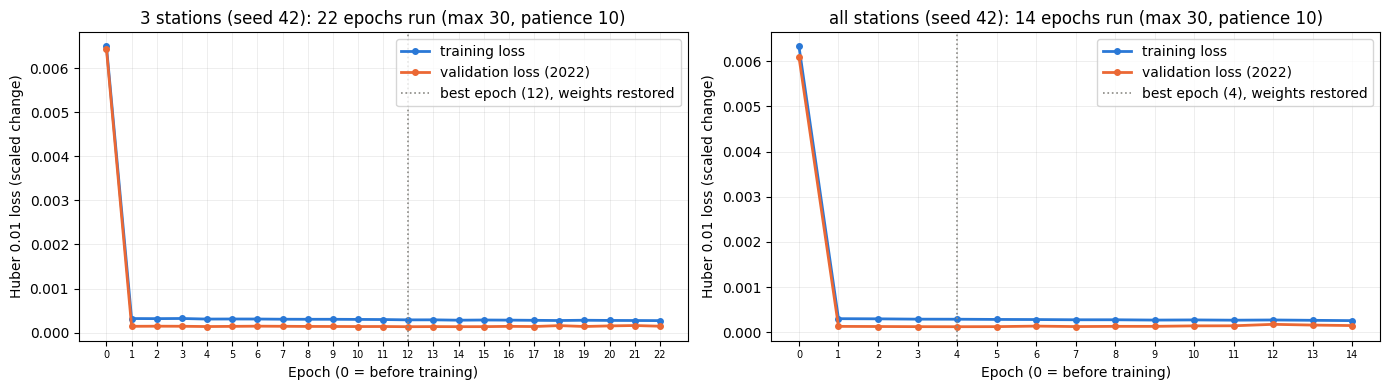

In [12]:
def plot_losses(results):
    """Training and validation loss per epoch, one panel per run."""
    fig, axes = plt.subplots(1, len(results), figsize=(7 * len(results), 4), squeeze=False)
    for ax, r in zip(axes.flat, results):
        epochs_axis = np.arange(len(r["history"]["train"]))
        ax.plot(epochs_axis, r["history"]["train"], color=C_ALL, linewidth=2, marker="o", markersize=4,
                label="training loss")
        ax.plot(epochs_axis, r["history"]["val"], color=C_LAST, linewidth=2, marker="o", markersize=4,
                label="validation loss (2022)")
        ax.axvline(r["best_epoch"], color=C_MUTED, linestyle=":", linewidth=1.2,
                   label=f"best epoch ({r['best_epoch']}), weights restored")
        ax.set_xticks(epochs_axis)
        ax.tick_params(axis="x", labelsize=7)
        ax.set_xlabel("Epoch (0 = before training)")
        ax.set_ylabel(f"Huber {HUBER_DELTA:g} loss (scaled change)")
        ax.set_title(f"{r['name']}: {r['epochs_run']} epochs run (max {EPOCHS}, patience {PATIENCE})")
        ax.grid(alpha=0.3, linewidth=0.5)
        ax.legend()
    plt.tight_layout()
    plt.show()


plot_losses([rs[0] for rs in runs.values()])

## 9. Linear baseline

A linear regression (Ridge) as a simple model to beat. Its inputs are the 7 inputs at the window's last hour plus SWC_20 and SWC_5 24 hours earlier, and it predicts the same scaled 72-hour change from the same training windows as the BiLSTM. It is fit once per station set and takes seconds. Ridge minimizes squared error, so it aims at RMSE rather than MAE.

In [13]:
I_SWC20, I_SWC5 = FEATURES.index("SWC_20"), FEATURES.index("SWC_5")


def ridge_inputs(w):
    """Last input hour (7 values) plus SWC_20 and SWC_5 24 hours before it."""
    return np.concatenate([w["X"][:, -1, :], w["X"][:, -25, [I_SWC20, I_SWC5]]], axis=1)


ridge_pred = {}
for set_name, stations in STATION_SETS.items():
    reg = Ridge(alpha=1.0).fit(ridge_inputs(TRAIN_WINDOWS[set_name]), TRAIN_WINDOWS[set_name]["y"])
    ridge_pred[set_name] = {p: SCORED[p]["last"] + reg.predict(ridge_inputs(SCORED[p])) * TARGET_SCALE
                            for p in ("val", "test")}
    print(f"Ridge, {set_name}: validation score {validation_score(ridge_pred[set_name]['val'], stations):+.2%}")


def forecasts(part):
    """Every forecast of one partition, as {name: [one forecast per seed]} (one entry for last value and Ridge)."""
    return {"Last value": [SCORED[part]["last"]],
            **{f"Ridge, {s}": [ridge_pred[s][part]] for s in STATION_SETS},
            **{f"BiLSTM, {s}": [r["pred"][part] for r in runs[s]] for s in STATION_SETS}}


GROUPS = {", ".join(THREE_STATIONS): THREE_STATIONS,
          "other training stations": [st for st in TRAIN_STATIONS if st not in THREE_STATIONS],
          "held-out stations": HELDOUT_STATIONS}

Ridge, 3 stations: validation score -20.74%
Ridge, all stations: validation score -27.94%


## 10. Does using more stations help?

The main table. Every forecast on the same windows, for three groups of stations: the 3-station set (FD11, CB25, FD02), the other training stations (which the 3-station model never saw), and the five held-out stations (which neither model saw). The BiLSTM rows are the mean of the three seeds, with the lowest and highest seed next to the skills. Look at the test rows of the 3-station set first: they show whether the extra stations help at the stations both models were trained on.

In [14]:
def group_rows(part):
    """Seed-mean scores of every forecast for each station group of one partition."""
    w = SCORED[part]
    rows = []
    for group, stations in GROUPS.items():
        m = np.isin(w["station"], stations)
        for name, preds in forecasts(part).items():
            mean, low, high = seed_scores(w, preds, m)
            rows.append({"partition": part, "group": group, "forecast": name, "windows": int(m.sum()),
                         "seeds": len(preds), "RMSE": mean["RMSE"], "RMSE_skill": mean["RMSE_skill"],
                         "RMSE_skill_lowest_seed": low["RMSE_skill"], "RMSE_skill_highest_seed": high["RMSE_skill"],
                         "MAE": mean["MAE"], "MAE_skill": mean["MAE_skill"],
                         "MAE_skill_lowest_seed": low["MAE_skill"], "MAE_skill_highest_seed": high["MAE_skill"],
                         "bias": mean["bias"], "change_corr": mean["change_corr"]})
    return rows


main_table = pd.DataFrame(group_rows("val") + group_rows("test")).set_index(["partition", "group", "forecast"])
show(main_table, "main_by_group")

windows  seeds     RMSE RMSE_skill RMSE_skill_lowest_seed RMSE_skill_highest_seed      MAE MAE_skill MAE_skill_lowest_seed MAE_skill_highest_seed     bias  change_corr
partition group                   forecast                                                                                                                                                                                     
val       FD11, CB25, FD02        Last value              25323      1  0.02030      +0.0%                  +0.0%                   +0.0%  0.00811     +0.0%                 +0.0%                  +0.0% -0.00020          NaN
                                  Ridge, 3 stations       25323      1  0.02013      +0.9%                  +0.9%                   +0.9%  0.01155    -42.3%                -42.3%                 -42.3%  0.00544        0.300
                                  Ridge, all stations     25323      1  0.01968      +3.0%                  +3.0%                   +3.0%  0.00989    -21.9%                -21.9%                 -21.9%  0.00307        0.288
                                  BiLSTM, 3 stations      25323      3  0.01930      +4.9%                  +4.4%                   +5.3%  0.00677    +16.6%                +12.6%                 +18.9% -0.00269        0.347
                                  BiLSTM, all stations    25323      3  0.01969      +3.0%                  +2.8%                   +3.5%  0.00662    +18.4%                +17.5%                 +19.6% -0.00342        0.298
          other training stations Last value             145167      1  0.01929      +0.0%                  +0.0%                   +0.0%  0.00704     +0.0%                 +0.0%                  +0.0% -0.00015          NaN
                                  Ridge, 3 stations      145167      1  0.02021      -4.8%                  -4.8%                   -4.8%  0.01363    -93.5%                -93.5%                 -93.5%  0.00776        0.282
                                  Ridge, all stations    145167      1  0.01934      -0.3%                  -0.3%                   -0.3%  0.01148    -63.0%                -63.0%                 -63.0%  0.00526        0.276
                                  BiLSTM, 3 stations     145167      3  0.01868      +3.2%                  +2.0%                   +4.0%  0.00671     +4.6%                 -0.4%                  +8.4% -0.00185        0.284
                                  BiLSTM, all stations   145167      3  0.01828      +5.2%                  +5.1%                   +5.5%  0.00579    +17.7%                +16.8%                 +18.7% -0.00218        0.346
          held-out stations       Last value              43205      1  0.02351      +0.0%                  +0.0%                   +0.0%  0.00884     +0.0%                 +0.0%                  +0.0% -0.00021          NaN
                                  Ridge, 3 stations       43205      1  0.02307      +1.9%                  +1.9%                   +1.9%  0.01417    -60.2%                -60.2%                 -60.2%  0.00696        0.359
                                  Ridge, all stations     43205      1  0.02263      +3.7%                  +3.7%                   +3.7%  0.01204    -36.1%                -36.1%                 -36.1%  0.00444        0.334
                                  BiLSTM, 3 stations      43205      3  0.02216      +5.7%                  +5.5%                   +6.1%  0.00733    +17.2%                +16.1%                 +18.5% -0.00225        0.367
                                  BiLSTM, all stations    43205      3  0.02231      +5.1%                  +5.0%                   +5.2%  0.00702    +20.6%                +19.8%                 +21.8% -0.00289        0.360
test      FD11, CB25, FD02        Last value              25755      1  0.03024      +0.0%                  +0.0%                   +0.0%  0.01547     +0.0%                 +0.0%                  +0.0%  0.00107          NaN
                        

Every metric on the 2024 test windows for each group: MSE, RMSE, MAE, MAPE and SMAPE (in %), RSE (squared error relative to the actual series' variance; below 1 is better than forecasting the mean), CORR and bias, each the mean over seeds. Lower is better for all but CORR.

In [15]:
w = SCORED["test"]
rows = []
for group, stations in GROUPS.items():
    m = np.isin(w["station"], stations)
    for name, preds in forecasts("test").items():
        per_seed = pd.DataFrame([compute_metrics(w["y_true"][m], p[m]) for p in preds])
        rows.append({"group": group, "forecast": name, **per_seed.mean()})
show(pd.DataFrame(rows).set_index(["group", "forecast"]), "test_all_metrics")

MSE     RMSE      MAE      MAPE     SMAPE      RSE   CORR     Bias
group                   forecast                                                                                    
FD11, CB25, FD02        Last value            0.00091  0.03024  0.01547   5.46738   5.73613  0.12587  0.937  0.00107
                        Ridge, 3 stations     0.00086  0.02935  0.01708   7.07977   7.23257  0.11858  0.940  0.00319
                        Ridge, all stations   0.00086  0.02924  0.01544   6.13827   6.37278  0.11775  0.939  0.00082
                        BiLSTM, 3 stations    0.00086  0.02928  0.01173   4.02412   4.39641  0.11807  0.941 -0.00451
                        BiLSTM, all stations  0.00088  0.02972  0.01162   3.91528   4.31479  0.12160  0.940 -0.00555
other training stations Last value            0.00080  0.02828  0.01363   7.25806   7.60303  0.09380  0.953  0.00121
                        Ridge, 3 stations     0.00076  0.02759  0.01741  18.91191  16.31726  0.08922  0.957  0.00625
                        Ridge, all stations   0.00074  0.02728  0.01587  16.62953  14.55824  0.08727  0.957  0.00405
                        BiLSTM, 3 stations    0.00073  0.02706  0.01132   8.78349   9.04057  0.08587  0.957 -0.00241
                        BiLSTM, all stations  0.00073  0.02700  0.01070   7.22205   7.62739  0.08547  0.957 -0.00352
held-out stations       Last value            0.00068  0.02600  0.01258   6.04842   6.31683  0.23455  0.884  0.00110
                        Ridge, 3 stations     0.00065  0.02543  0.01595   8.35931   8.51517  0.22429  0.890  0.00551
                        Ridge, all stations   0.00063  0.02509  0.01429   7.31539   7.56726  0.21828  0.890  0.00325
                        BiLSTM, 3 stations    0.00062  0.02493  0.01034   4.83886   5.31468  0.21556  0.893 -0.00298
                        BiLSTM, all stations  0.00062  0.02485  0.00992   4.59180   5.06702  0.21420  0.893 -0.00338

The same comparison for each station in 2024: last value's error and the RMSE and MAE skill of the two BiLSTMs (mean of three seeds). `diff_` columns are the all-station model minus the 3-station model, so a positive value means the extra stations helped at that station. Stations with fewer than 1,000 test windows are marked `few_windows`; their skills move a lot with a single storm. Stations with no usable 2024 windows are left out.

In [16]:
w = SCORED["test"]
rows = []
for st in SCORED_STATIONS:
    m = w["station"] == st
    if not m.any():
        continue
    lv = scores(w, w["last"], m)
    three = seed_scores(w, forecasts("test")["BiLSTM, 3 stations"], m)[0]
    allst = seed_scores(w, forecasts("test")["BiLSTM, all stations"], m)[0]
    rows.append({"station": st, "role": role(st), "windows": int(m.sum()), "few_windows": m.sum() < MIN_TEST_WINDOWS,
                 "last_value_RMSE": lv["RMSE"], "last_value_MAE": lv["MAE"],
                 "3_stations_RMSE_skill": three["RMSE_skill"], "all_stations_RMSE_skill": allst["RMSE_skill"],
                 "diff_RMSE_skill": allst["RMSE_skill"] - three["RMSE_skill"],
                 "3_stations_MAE_skill": three["MAE_skill"], "all_stations_MAE_skill": allst["MAE_skill"],
                 "diff_MAE_skill": allst["MAE_skill"] - three["MAE_skill"]})
per_station = pd.DataFrame(rows).set_index("station")
show(per_station, "test_by_station")

,role,windows,few_windows,last_value_RMSE,last_value_MAE,3_stations_RMSE_skill,all_stations_RMSE_skill,diff_RMSE_skill,3_stations_MAE_skill,all_stations_MAE_skill,diff_MAE_skill
station,,,,,,,,,,,
CB01,training,1762,False,0.01177,0.00852,+11.6%,+7.7%,-3.9%,+29.5%,+27.1%,-2.4%
CB07,training,514,True,0.03011,0.01624,+0.6%,+1.6%,+1.0%,+6.2%,+8.8%,+2.5%
CB10,training,6819,False,0.02512,0.01439,+6.0%,+5.8%,-0.1%,+20.6%,+26.8%,+6.2%
CB19,training,8665,False,0.01824,0.01055,+1.5%,+3.2%,+1.7%,+12.5%,+19.1%,+6.6%
CB20,training,1765,False,0.01670,0.01223,+10.0%,+8.4%,-1.6%,+20.9%,+23.5%,+2.6%
CB25,3-station set,8545,False,0.03830,0.02236,+1.6%,+1.4%,-0.2%,+23.4%,+23.7%,+0.3%
CB26,training,4869,False,0.00639,0.00486,+1.3%,-5.6%,-7.0%,+4.1%,-6.3%,-10.3%
CB27,training,1763,False,0.01236,0.00971,+12.6%,+13.1%,+0.5%,+19.0%,+30.6%,+11.6%
CB31,training,6721,False,0.02067,0.01209,+0.8%,+1.1%,+0.3%,+22.8%,+26.5%,+3.7%


The per-station table as bars: aqua is the 3-station BiLSTM and blue the all-station BiLSTM, both the mean of three seeds. Held-out stations and stations with few test windows are named as such in the labels. Bars right of the zero line beat last value.

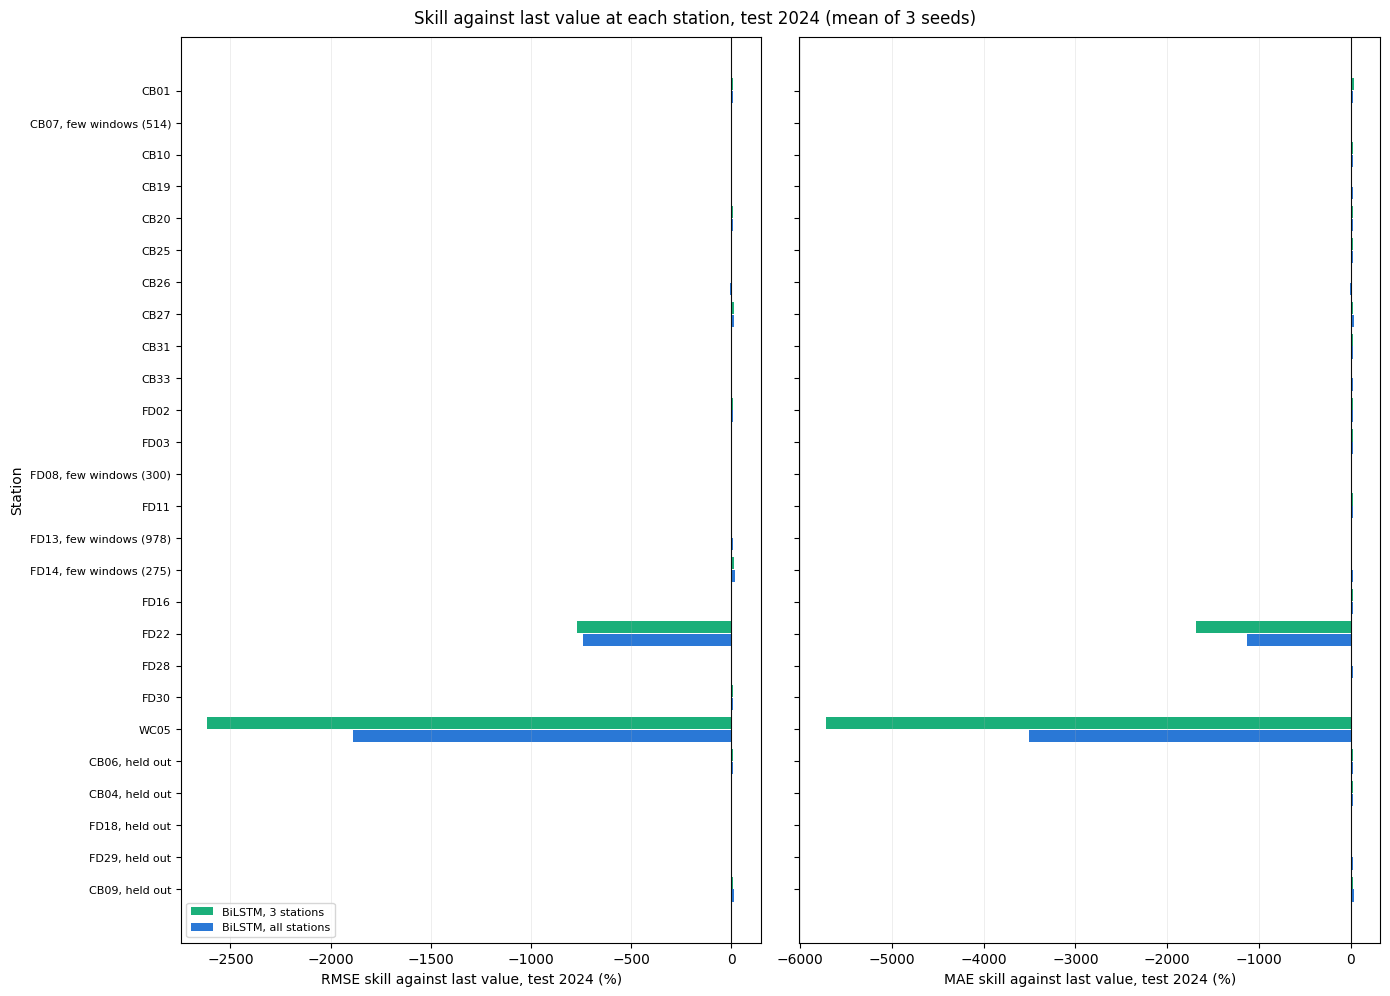

In [17]:
order = list(per_station.index)[::-1]                      # first station of the table at the top
labels = [st + (", held out" if per_station.loc[st, "role"] == "held out" else "")
          + (f", few windows ({per_station.loc[st, 'windows']})" if per_station.loc[st, "few_windows"] else "")
          for st in order]
y = np.arange(len(order))
fig, axes = plt.subplots(1, 2, figsize=(14, 0.32 * len(order) + 1.8), sharey=True)
for ax, metric in zip(axes, ("RMSE", "MAE")):
    ax.barh(y + 0.2, per_station.loc[order, f"3_stations_{metric}_skill"] * 100, height=0.38, color=C_THREE,
            label="BiLSTM, 3 stations")
    ax.barh(y - 0.2, per_station.loc[order, f"all_stations_{metric}_skill"] * 100, height=0.38, color=C_ALL,
            label="BiLSTM, all stations")
    ax.axvline(0, color=C_ACTUAL, linewidth=0.8)
    ax.set_xlabel(f"{metric} skill against last value, test 2024 (%)")
    ax.grid(axis="x", alpha=0.3, linewidth=0.5)
axes[0].set_yticks(y)
axes[0].set_yticklabels(labels, fontsize=8)
axes[0].set_ylabel("Station")
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle(f"Skill against last value at each station, test 2024 (mean of {len(SEEDS)} seeds)")
plt.tight_layout()
plt.show()

## 11. Rain in the forecast gap

Skill split by whether at least 2 mm of rain fell in the 72 hours between the window and its target, for each group and both BiLSTMs (mean of three seeds). The model cannot see that rain. In three_stations_72h about a quarter of the test windows had gap rain, and they held over 80% of last value's squared error, so this split shows the part of the error the model can work on (no gap rain, mostly drying) and the part it cannot (gap rain).

In [18]:
rows = []
for part in ("val", "test"):
    w = SCORED[part]
    for group, stations in GROUPS.items():
        m = np.isin(w["station"], stations)
        w_group = subset(w, m)
        for name in (f"BiLSTM, {s}" for s in STATION_SETS):
            per_seed = [pd.DataFrame(gap_rain_split(w_group, p[m])).set_index("windows")
                        for p in forecasts(part)[name]]
            mean = sum(per_seed) / len(per_seed)
            for label, row in mean.iterrows():
                rows.append({"partition": part, "group": group, "forecast": name, "windows": label,
                             **row, "count": int(row["count"])})
show(pd.DataFrame(rows).set_index(["partition", "group", "forecast", "windows"]), "gap_rain")

count share_of_windows share_of_last_value_sq_error RMSE_skill MAE_skill     bias  last_value_bias
partition group                   forecast             windows                                                                                                                  
val       FD11, CB25, FD02        BiLSTM, 3 stations   no gap rain (< 2 mm)   20836            82.3%                        15.6%     +36.8%    +26.8%  0.00051          0.00305
                                                       gap rain (>= 2 mm)      4487            17.7%                        84.4%      +0.2%     +5.3% -0.01751         -0.01532
                                  BiLSTM, all stations no gap rain (< 2 mm)   20836            82.3%                        15.6%     +39.5%    +33.0% -0.00021          0.00305
                                                       gap rain (>= 2 mm)      4487            17.7%                        84.4%      -2.3%     +2.2% -0.01836         -0.01532
          other training stations BiLSTM, 3 stations   no gap rain (< 2 mm)  121535            83.7%                        19.4%     +12.6%     +9.5%  0.00094          0.00278
                                                       gap rain (>= 2 mm)     23632            16.3%                        80.6%      +1.1%     -1.3% -0.01620         -0.01521
                                  BiLSTM, all stations no gap rain (< 2 mm)  121535            83.7%                        19.4%     +27.8%    +31.4%  0.00064          0.00278
                                                       gap rain (>= 2 mm)     23632            16.3%                        80.6%      +0.5%     +1.1% -0.01667         -0.01521
          held-out stations       BiLSTM, 3 stations   no gap rain (< 2 mm)   34879            80.7%                        15.9%     +31.8%    +32.9%  0.00184          0.00405
                                                       gap rain (>= 2 mm)      8326            19.3%                        84.1%      +1.6%     +2.6% -0.01938         -0.01809
                                  BiLSTM, all stations no gap rain (< 2 mm)   34879            80.7%                        15.9%     +35.2%    +40.1%  0.00120          0.00405
                                                       gap rain (>= 2 mm)      8326            19.3%                        84.1%      +0.4%     +2.7% -0.02005         -0.01809
test      FD11, CB25, FD02        BiLSTM, 3 stations   no gap rain (< 2 mm)   19023            73.9%                        16.4%     +47.5%    +50.0%  0.00347          0.00912
                                                       gap rain (>= 2 mm)      6732            26.1%                        83.6%      -3.3%     +1.3% -0.02706         -0.02170
                                  BiLSTM, all stations no gap rain (< 2 mm)   19023            73.9%                        16.4%     +51.1%    +54.3%  0.00255          0.00912
                                                       gap rain (>= 2 mm)      6732            26.1%                        83.6%      -5.3%     -1.2% -0.02844         -0.02170
          other training stations BiLSTM, 3 stations   no gap rain (< 2 mm)   50329            75.2%                        34.9%     +16.9%    +31.3%  0.00350          0.00736
                                                       gap rain (>= 2 mm)     16628            24.8%                        65.1%      -1.8%     -1.0% -0.02030         -0.01740
                                  BiLSTM, all stations no gap rain (< 2 mm)   50329            75.2%                        34.9%     +19.9%    +40.4%  0.00253          0.00736
                                                       gap rain (>= 2 mm)     16628            24.8%                        65.1%      -2.8%     -2.0% -0.02183         -0.01740
          held-out stations       BiLSTM, 3 stations   no gap rain (< 2 mm)   29131            76.3%                        38.2%     +10.2%    +27.7%  0.00086          0.00536
       

## 12. Forecast or copy

For each group in 2024: `change_corr`, the mean `lag_hours` over the group's stations, and the forecast rises (a forecast rise of more than 0.02 while `SWC_20` rose by less than 0.005 counts as a false rise). BiLSTM values are the mean of three seeds. Last value has a lag of exactly 72 and no change_corr.

In [19]:
w = SCORED["test"]
rows = []
for group, stations in GROUPS.items():
    m = np.isin(w["station"], stations)
    for name, preds in forecasts("test").items():
        per_seed = []
        for p in preds:
            n_rises, n_false = false_rises(subset(w, m), p[m])
            per_seed.append({"change_corr": scores(w, p, m)["change_corr"],
                             "lag_hours": np.nanmean([lag_hours(w, p, st) for st in stations]),
                             "forecast_rises": n_rises, "false_rises": n_false})
        rows.append({"group": group, "forecast": name, **pd.DataFrame(per_seed).mean()})
show(pd.DataFrame(rows).set_index(["group", "forecast"]), "forecast_or_copy")

change_corr  lag_hours  forecast_rises  false_rises
group                   forecast                                                                 
FD11, CB25, FD02        Last value                    NaN       72.0         0.00000      0.00000
                        Ridge, 3 stations           0.265       70.3       426.00000    266.00000
                        Ridge, all stations         0.255       69.3       265.00000    153.00000
                        BiLSTM, 3 stations          0.291       62.1        90.00000     30.33333
                        BiLSTM, all stations        0.259       57.0        27.66667     10.33333
other training stations Last value                    NaN       72.0         0.00000      0.00000
                        Ridge, 3 stations           0.310       63.7      1867.00000   1222.00000
                        Ridge, all stations         0.297       63.7      1031.00000    651.00000
                        BiLSTM, 3 stations          0.305       63.7       174.66667     54.33333
                        BiLSTM, all stations        0.328       60.0        69.33333     22.66667
held-out stations       Last value                    NaN       72.0         0.00000      0.00000
                        Ridge, 3 stations           0.299       70.4       571.00000    277.00000
                        Ridge, all stations         0.292       68.4       345.00000    156.00000
                        BiLSTM, 3 stations          0.305       64.6        80.66667      8.33333
                        BiLSTM, all stations        0.324       60.9        49.00000      1.33333

## 13. Overfitting check

RMSE and MAE against last value for each BiLSTM on its own training stations, on the training windows (every 5th, the ones it was trained on), validation and test (mean of three seeds). Skill much higher on training than on validation and test means the model is overfitting the training years; skill that holds across the three means it generalizes.

In [20]:
rows = []
for set_name, rs in runs.items():
    stations = STATION_SETS[set_name]
    windows = {"train": TRAIN_WINDOWS[set_name], **{p: own_stations(SCORED[p], stations) for p in ("val", "test")}}
    for part, w in windows.items():
        if part == "train":
            preds = [predict(r["model"], w) for r in rs]
        else:
            preds = [r["pred"][part][np.isin(SCORED[part]["station"], stations)] for r in rs]
        mean = seed_scores(w, preds)[0]
        lv = scores(w, w["last"])
        rows.append({"model": f"BiLSTM, {set_name}", "partition": part, "windows": len(w["y"]),
                     "model_RMSE": mean["RMSE"], "last_value_RMSE": lv["RMSE"], "RMSE_skill": mean["RMSE_skill"],
                     "model_MAE": mean["MAE"], "last_value_MAE": lv["MAE"], "MAE_skill": mean["MAE_skill"],
                     "model_bias": mean["bias"]})
show(pd.DataFrame(rows).set_index(["model", "partition"]), "overfitting_check")

windows  model_RMSE  last_value_RMSE RMSE_skill  model_MAE  last_value_MAE MAE_skill  model_bias
model                partition                                                                                                  
BiLSTM, 3 stations   train        36410     0.03055          0.03188      +4.2%    0.01187         0.01573    +24.5%    -0.00627
                     val          25323     0.01930          0.02030      +4.9%    0.00677         0.00811    +16.6%    -0.00269
                     test         25755     0.02928          0.03024      +3.1%    0.01173         0.01547    +24.2%    -0.00451
BiLSTM, all stations train       264857     0.02946          0.03065      +3.9%    0.01179         0.01477    +20.1%    -0.00514
                     val         170490     0.01850          0.01944      +4.9%    0.00592         0.00720    +17.8%    -0.00237
                     test         92712     0.02778          0.02884      +3.7%    0.01095         0.01414    +22.5%    -0.00408

## 14. Plots

The 2024 test year at the 3-station set and two held-out stations: actual `SWC_20`, the two BiLSTMs (seed 42) and last value, by target time. Gaps in the lines are hours whose window was dropped because an input or the target was filled in.

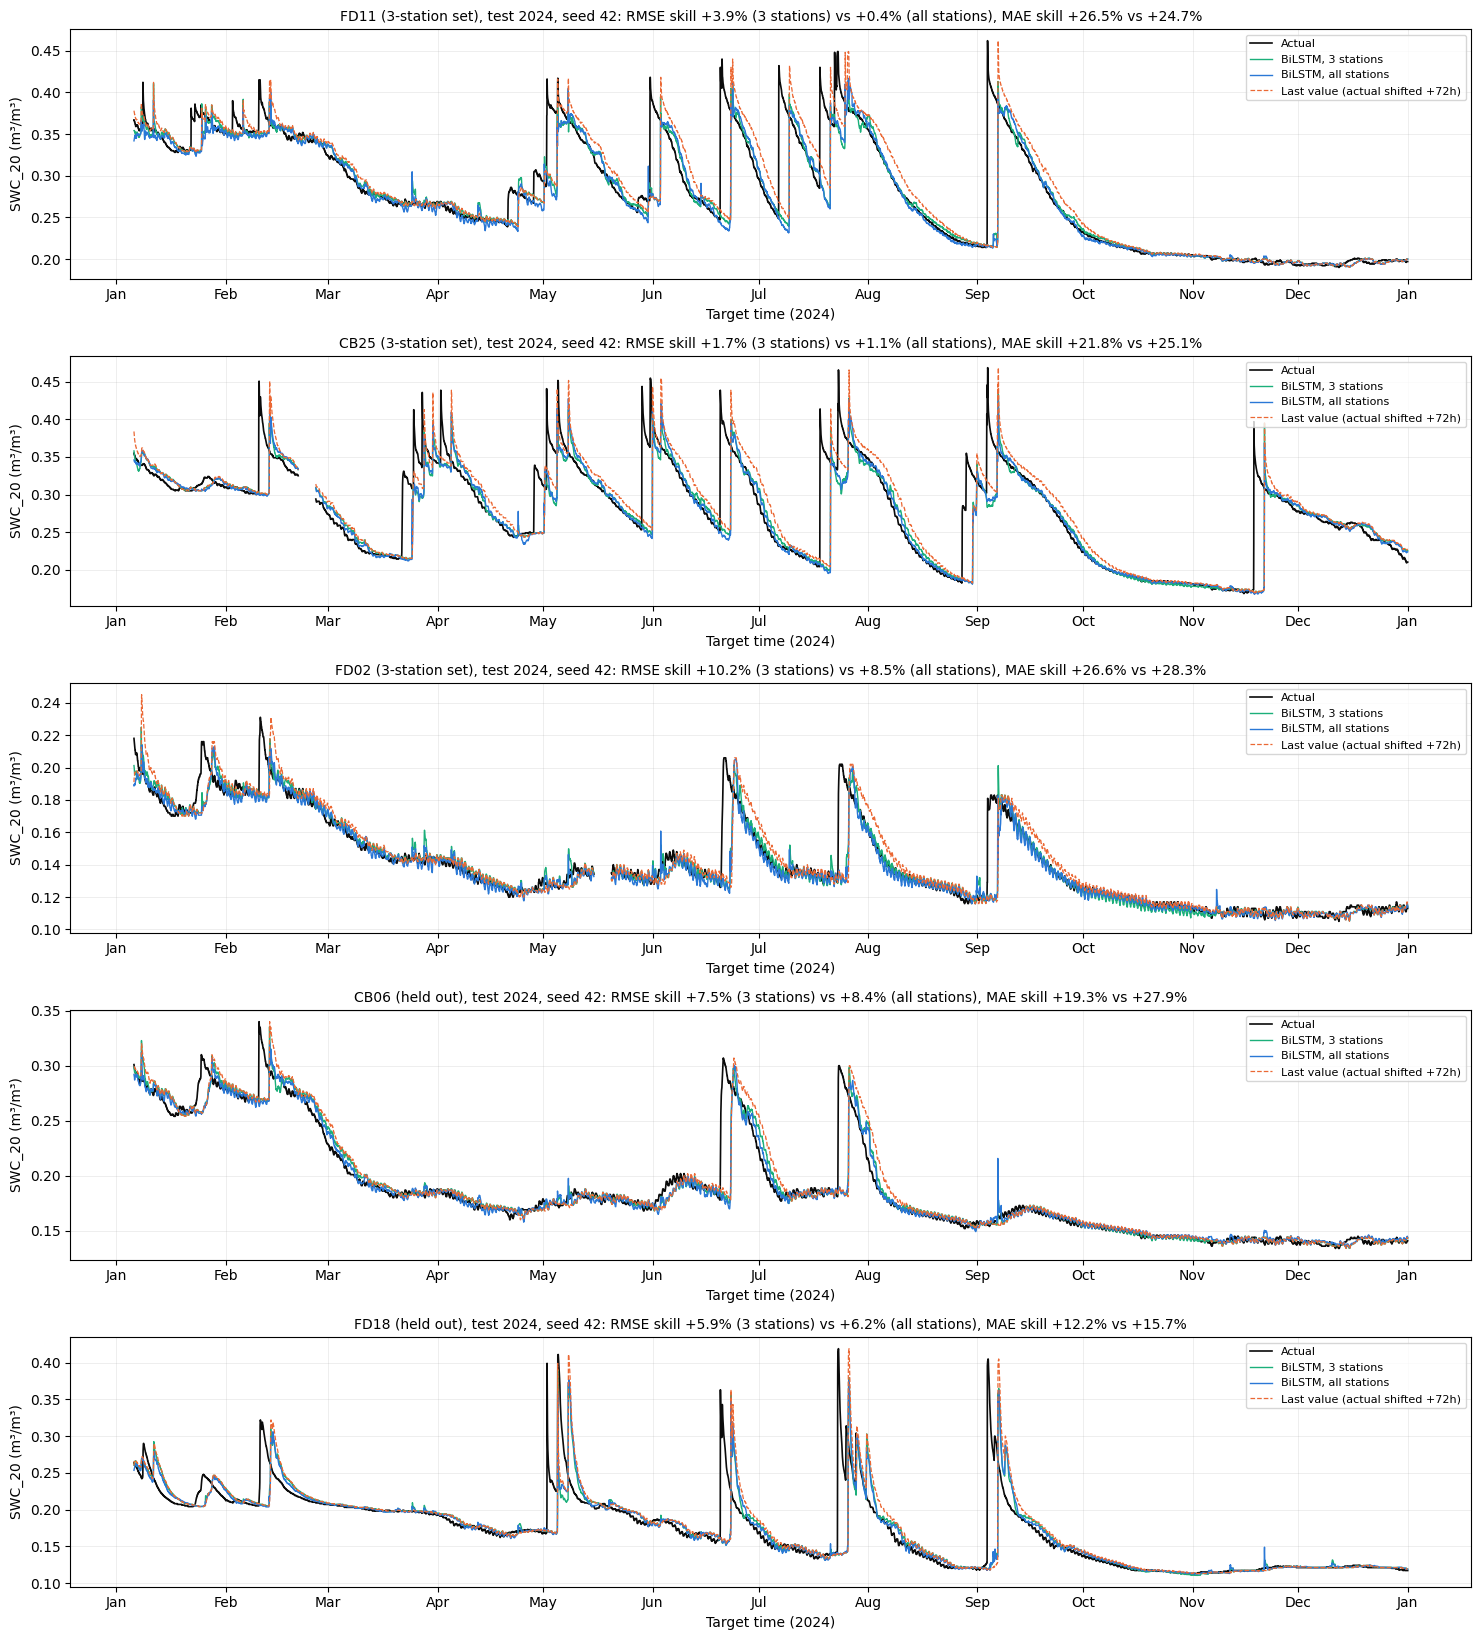

In [21]:
w = SCORED["test"]
plot_stations = [st for st in THREE_STATIONS + ["CB06", "FD18"] if (w["station"] == st).any()]


def hourly(values, m):
    """values of the windows in m as an hourly series by target time; NaN where a window is missing, so gaps show."""
    return pd.Series(values[m], index=pd.DatetimeIndex(w["target_time"][m])).asfreq("h")


fig, axes = plt.subplots(len(plot_stations), 1, figsize=(15, 3.3 * len(plot_stations)), squeeze=False)
for ax, st in zip(axes.flat, plot_stations):
    m = w["station"] == st
    s_all = scores(w, runs["all stations"][0]["pred"]["test"], m)
    s_three = scores(w, runs["3 stations"][0]["pred"]["test"], m)
    ax.plot(hourly(w["y_true"], m), color=C_ACTUAL, linewidth=1.2, label="Actual")
    ax.plot(hourly(runs["3 stations"][0]["pred"]["test"], m), color=C_THREE, linewidth=1.0, label="BiLSTM, 3 stations")
    ax.plot(hourly(runs["all stations"][0]["pred"]["test"], m), color=C_ALL, linewidth=1.0, label="BiLSTM, all stations")
    ax.plot(hourly(w["last"], m), color=C_LAST, linewidth=0.9, linestyle="--",
            label=f"Last value (actual shifted +{HORIZON}h)")
    ax.set_title(f"{st} ({role(st)}), test 2024, seed 42: RMSE skill {s_three['RMSE_skill']:+.1%} (3 stations) vs "
                 f"{s_all['RMSE_skill']:+.1%} (all stations), MAE skill {s_three['MAE_skill']:+.1%} vs "
                 f"{s_all['MAE_skill']:+.1%}", fontsize=10)
    ax.set_xlabel("Target time (2024)")
    ax.set_ylabel("SWC_20 (m³/m³)")
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.grid(alpha=0.3, linewidth=0.5)
    ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

FD11 in 2024 by target month, as in combined_10yr, for the all-station BiLSTM (seed 42), with the monthly scores in the table. Each panel has its own y-axis, and the last-value line is the actual series shifted right by 72 hours.

,model_RMSE,last_value_RMSE,model_MAE,last_value_MAE,model_bias,last_value_bias,model_better_MAE
target month,,,,,,,
2024-01,0.01868,0.01827,0.01242,0.01320,-0.00862,0.00177,True
2024-02,0.01441,0.01569,0.00913,0.01132,-0.00459,0.00206,True
2024-03,0.00619,0.00909,0.00492,0.00695,0.00141,0.00649,True
2024-04,0.01731,0.01540,0.01057,0.00987,-0.00710,-0.00308,False
2024-05,0.03832,0.03669,0.02141,0.02481,-0.01234,-0.00072,True
2024-06,0.05903,0.05975,0.03192,0.04340,-0.01595,-0.00100,True
2024-07,0.06190,0.05713,0.03735,0.04509,-0.02440,-0.00487,True
2024-08,0.00345,0.01620,0.00301,0.01433,-0.00099,0.01433,True
2024-09,0.05938,0.06306,0.02360,0.03594,-0.01476,-0.00194,True


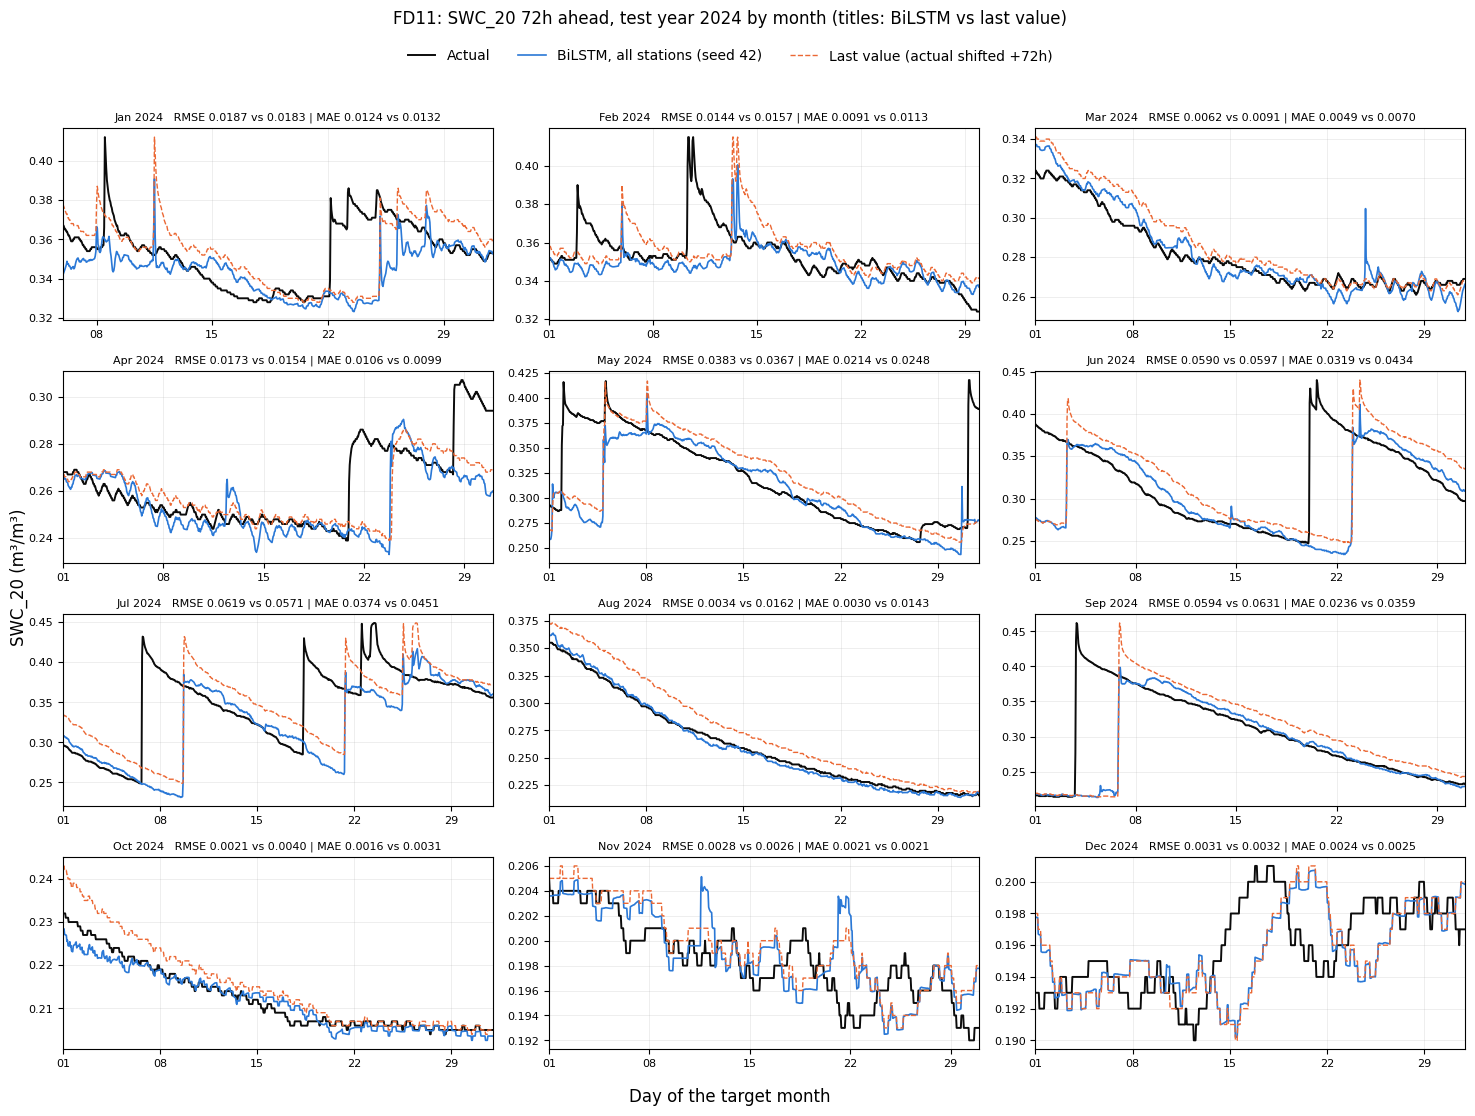

In [22]:
w, pred = SCORED["test"], runs["all stations"][0]["pred"]["test"]
m = w["station"] == "FD11"
monthly = pd.DataFrame({"actual": w["y_true"][m], "model": pred[m], "last_value": w["last"][m]},
                       index=pd.DatetimeIndex(w["target_time"][m]))


def month_scores(g):
    mod, last = compute_metrics(g["actual"], g["model"]), compute_metrics(g["actual"], g["last_value"])
    return pd.Series({"model_RMSE": mod["RMSE"], "last_value_RMSE": last["RMSE"], "model_MAE": mod["MAE"],
                      "last_value_MAE": last["MAE"], "model_bias": mod["Bias"], "last_value_bias": last["Bias"]})


by_month = monthly.groupby(monthly.index.to_period("M")).apply(month_scores)
by_month["model_better_MAE"] = by_month["model_MAE"] < by_month["last_value_MAE"]
by_month.index.name = "target month"
show(by_month, "fd11_by_month")

months = by_month.index
ncols = 3
nrows = int(np.ceil(len(months) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 2.7 * nrows), squeeze=False)
for ax, month in zip(axes.flat, months):
    g = monthly[monthly.index.to_period("M") == month]
    ax.plot(g.index, g["actual"], color=C_ACTUAL, linewidth=1.4, label="Actual")
    ax.plot(g.index, g["model"], color=C_ALL, linewidth=1.2, label="BiLSTM, all stations (seed 42)")
    ax.plot(g.index, g["last_value"], color=C_LAST, linewidth=1.0, linestyle="--",
            label=f"Last value (actual shifted +{HORIZON}h)")
    s = by_month.loc[month]
    ax.set_title(f"{month.strftime('%b %Y')}   RMSE {s['model_RMSE']:.4f} vs {s['last_value_RMSE']:.4f} | "
                 f"MAE {s['model_MAE']:.4f} vs {s['last_value_MAE']:.4f}", fontsize=8)
    ax.set_xlim(g.index.min(), g.index.max())
    ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 8, 15, 22, 29]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d"))
    ax.tick_params(labelsize=8)
    ax.grid(alpha=0.3, linewidth=0.5)
for ax in axes.flat[len(months):]:
    ax.set_visible(False)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.suptitle(f"FD11: SWC_20 {HORIZON}h ahead, test year 2024 by month (titles: BiLSTM vs last value)", y=1.025)
fig.supxlabel("Day of the target month")
fig.supylabel("SWC_20 (m³/m³)")
plt.tight_layout(rect=(0, 0, 1, 0.975))
plt.show()

## 15. Comparison with older notebooks

FD11 test 2024 scores of the older notebooks, copied from their saved outputs, next to this notebook's FD11 rows (mean of three seeds for the BiLSTMs).

In [23]:
w = SCORED["test"]
fd11 = w["station"] == "FD11"
rows = [
    {"notebook": "akhil_lstm_72h (10/29)", "setup": "FD11, train 2019-21, 24 h window, 11 inputs, 1-layer LSTM",
     "RMSE": 0.03298, "MAE": 0.01369, "RMSE_skill": 0.014, "MAE_skill": 0.230},
    {"notebook": "combined_10yr combined", "setup": "FD11, train 2015-21, 48 h window, the 7 inputs",
     "RMSE": 0.03291, "MAE": 0.01265, "RMSE_skill": 0.016, "MAE_skill": 0.288},
    {"notebook": "three_stations_72h new model", "setup": "FD11+CB25+FD02, every training window, Huber 0.01, one seed",
     "RMSE": 0.03216, "MAE": 0.01269, "RMSE_skill": 0.039, "MAE_skill": 0.285},
]
for name, preds in forecasts("test").items():
    if name == "Last value":
        continue
    mean = seed_scores(w, preds, fd11)[0]
    rows.append({"notebook": f"this notebook: {name}", "setup": f"every {TRAIN_STRIDE}th training window, "
                 f"{len(preds)} seed(s)", "RMSE": mean["RMSE"], "MAE": mean["MAE"],
                 "RMSE_skill": mean["RMSE_skill"], "MAE_skill": mean["MAE_skill"]})
lv = scores(w, w["last"], fd11)
rows.append({"notebook": "last value", "setup": "same FD11 windows as combined_10yr", "RMSE": lv["RMSE"],
             "MAE": lv["MAE"], "RMSE_skill": np.nan, "MAE_skill": np.nan})
show(pd.DataFrame(rows).set_index("notebook"), "comparison_older_notebooks")

,setup,RMSE,MAE,RMSE_skill,MAE_skill
notebook,,,,,
akhil_lstm_72h (10/29),"FD11, train 2019-21, 24 h window, 11 inputs, 1...",0.03298,0.01369,+1.4%,+23.0%
combined_10yr combined,"FD11, train 2015-21, 48 h window, the 7 inputs",0.03291,0.01265,+1.6%,+28.8%
three_stations_72h new model,"FD11+CB25+FD02, every training window, Huber 0...",0.03216,0.01269,+3.9%,+28.5%
"this notebook: Ridge, 3 stations","every 5th training window, 1 seed(s)",0.03223,0.01985,+3.6%,-11.8%
"this notebook: Ridge, all stations","every 5th training window, 1 seed(s)",0.03211,0.01788,+4.0%,-0.7%
"this notebook: BiLSTM, 3 stations","every 5th training window, 3 seed(s)",0.03191,0.01320,+4.6%,+25.6%
"this notebook: BiLSTM, all stations","every 5th training window, 3 seed(s)",0.03306,0.01329,+1.2%,+25.1%
last value,same FD11 windows as combined_10yr,0.03345,0.01775,,


akhil_lstm_72h's skill is measured against last value on its own 24 h windows, so its last value differs slightly from the 48 h windows. The test_ppt feature tests and lstm_72_new are left out because they predict a daily mean, not the hourly value.

## 16. Summary

Prints the test 2024 skill of both BiLSTMs for each station group (mean of three seeds, with the seed range), the Ridge baseline, and the skill in windows without gap rain.

In [24]:
test_rows = main_table.loc["test"]
print(f"Training stations: {len(TRAIN_STATIONS)} (all stations) against {len(THREE_STATIONS)} (3 stations); "
      f"held out: {', '.join(HELDOUT_STATIONS)}.")
for group in GROUPS:
    print(f"\nTest 2024, {group} ({int(test_rows.loc[(group, 'Last value'), 'windows'])} windows):")
    for name in ("Ridge, all stations", "BiLSTM, 3 stations", "BiLSTM, all stations"):
        r = test_rows.loc[(group, name)]
        seed_range = (f" (seeds {r['RMSE_skill_lowest_seed']:+.1%} to {r['RMSE_skill_highest_seed']:+.1%}; "
                      f"{r['MAE_skill_lowest_seed']:+.1%} to {r['MAE_skill_highest_seed']:+.1%})"
                      if r["seeds"] > 1 else "")
        print(f"  {name}: RMSE skill {r['RMSE_skill']:+.1%}, MAE skill {r['MAE_skill']:+.1%}{seed_range}, "
              f"bias {r['bias']:+.5f}")

w = SCORED["test"]
no_rain = w["gap_rain"] < GAP_RAIN_MM
for name in (f"BiLSTM, {s}" for s in STATION_SETS):
    mean = seed_scores(w, forecasts("test")[name], no_rain)[0]
    print(f"\n{name}, test windows without gap rain, all scored stations: RMSE skill {mean['RMSE_skill']:+.1%}, "
          f"MAE skill {mean['MAE_skill']:+.1%}")

Training stations: 26 (all stations) against 3 (3 stations); held out: CB06, CB04, FD18, FD29, CB09.

Test 2024, FD11, CB25, FD02 (25755 windows):
  Ridge, all stations: RMSE skill +3.3%, MAE skill +0.2%, bias +0.00082
  BiLSTM, 3 stations: RMSE skill +3.1%, MAE skill +24.2% (seeds +3.0% to +3.4%; +24.1% to +24.3%), bias -0.00451
  BiLSTM, all stations: RMSE skill +1.7%, MAE skill +24.9% (seeds +1.2% to +2.0%; +23.4% to +25.9%), bias -0.00555

Test 2024, other training stations (66957 windows):
  Ridge, all stations: RMSE skill +3.5%, MAE skill -16.5%, bias +0.00405
  BiLSTM, 3 stations: RMSE skill +4.3%, MAE skill +16.9% (seeds +4.2% to +4.5%; +15.8% to +17.6%), bias -0.00241
  BiLSTM, all stations: RMSE skill +4.5%, MAE skill +21.5% (seeds +4.1% to +4.8%; +20.9% to +22.6%), bias -0.00352

Test 2024, held-out stations (38195 windows):
  Ridge, all stations: RMSE skill +3.5%, MAE skill -13.6%, bias +0.00325
  BiLSTM, 3 stations: RMSE skill +4.1%, MAE skill +17.8% (seeds +4.0% to +4.2%;